In [1]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content/olist_cleaned')

print("Cleaned datasets extracted successfully!")
print("Total files:", len(os.listdir('/content/olist_cleaned')))

Saving olist_cleaned_datasets (1).zip to olist_cleaned_datasets (1).zip
Cleaned datasets extracted successfully!
Total files: 9


In [2]:
import pandas as pd
import os

data_path = '/content/olist_cleaned/'

customers = pd.read_csv(data_path + 'customers_clean.csv')
orders = pd.read_csv(data_path + 'orders_clean.csv')
order_items = pd.read_csv(data_path + 'order_items_clean.csv')
payments = pd.read_csv(data_path + 'payments_clean.csv')
reviews = pd.read_csv(data_path + 'reviews_clean.csv')
products = pd.read_csv(data_path + 'products_clean.csv')
sellers = pd.read_csv(data_path + 'sellers_clean.csv')
geolocation = pd.read_csv(data_path + 'geolocation_clean.csv')
category_translation = pd.read_csv(data_path + 'category_translation_clean.csv')

print("All 9 cleaned datasets loaded successfully!")

datasets = {
    'Customers': customers,
    'Orders': orders,
    'Order Items': order_items,
    'Payments': payments,
    'Reviews': reviews,
    'Products': products,
    'Sellers': sellers,
    'Geolocation': geolocation,
    'Category Translation': category_translation
}

for name, df in datasets.items():
    print(f"{name}: {len(df):,} rows")

All 9 cleaned datasets loaded successfully!
Customers: 99,441 rows
Orders: 99,441 rows
Order Items: 112,650 rows
Payments: 103,886 rows
Reviews: 99,224 rows
Products: 32,951 rows
Sellers: 3,095 rows
Geolocation: 738,332 rows
Category Translation: 71 rows


In [3]:
# Filter delivered orders
delivered_orders = orders[
    orders['order_status'] == 'delivered'
]

# Get items belonging to delivered orders
delivered_items = order_items[
    order_items['order_id'].isin(delivered_orders['order_id'])
]

# Calculate sales KPIs
total_orders = delivered_orders['order_id'].nunique()

total_items = len(delivered_items)

total_revenue = delivered_items['price'].sum()

average_order_value = total_revenue / total_orders

print("ECOMMERCE SALES PERFORMANCE")
print("-" * 35)

print("Delivered Orders:", f"{total_orders:,}")
print("Total Items Sold:", f"{total_items:,}")
print("Product Sales Revenue: R$", f"{total_revenue:,.2f}")
print("Average Order Value: R$", f"{average_order_value:,.2f}")

ECOMMERCE SALES PERFORMANCE
-----------------------------------
Delivered Orders: 96,478
Total Items Sold: 110,197
Product Sales Revenue: R$ 13,221,498.11
Average Order Value: R$ 137.04


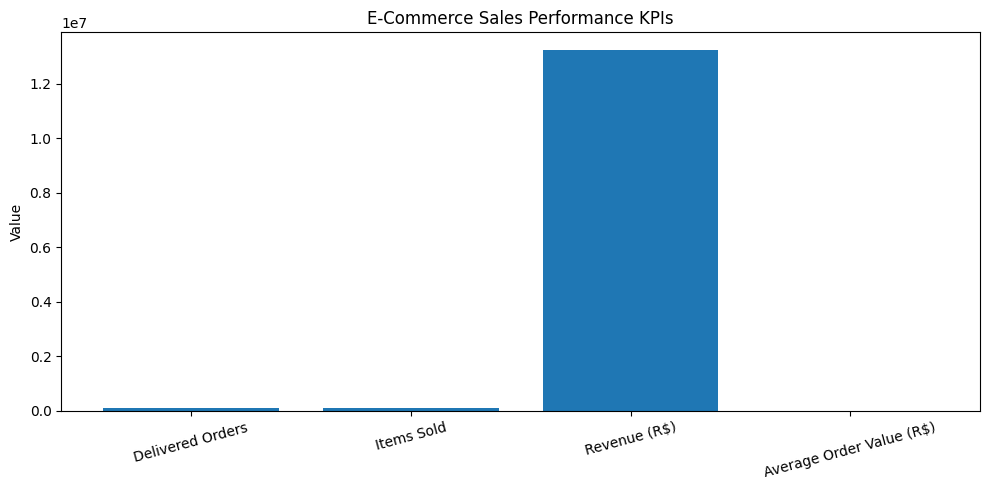

In [4]:
import matplotlib.pyplot as plt

kpi_names = [
    'Delivered Orders',
    'Items Sold',
    'Revenue (R$)',
    'Average Order Value (R$)'
]

kpi_values = [
    total_orders,
    total_items,
    total_revenue,
    average_order_value
]

plt.figure(figsize=(10, 5))

plt.bar(kpi_names, kpi_values)

plt.title('E-Commerce Sales Performance KPIs')
plt.ylabel('Value')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

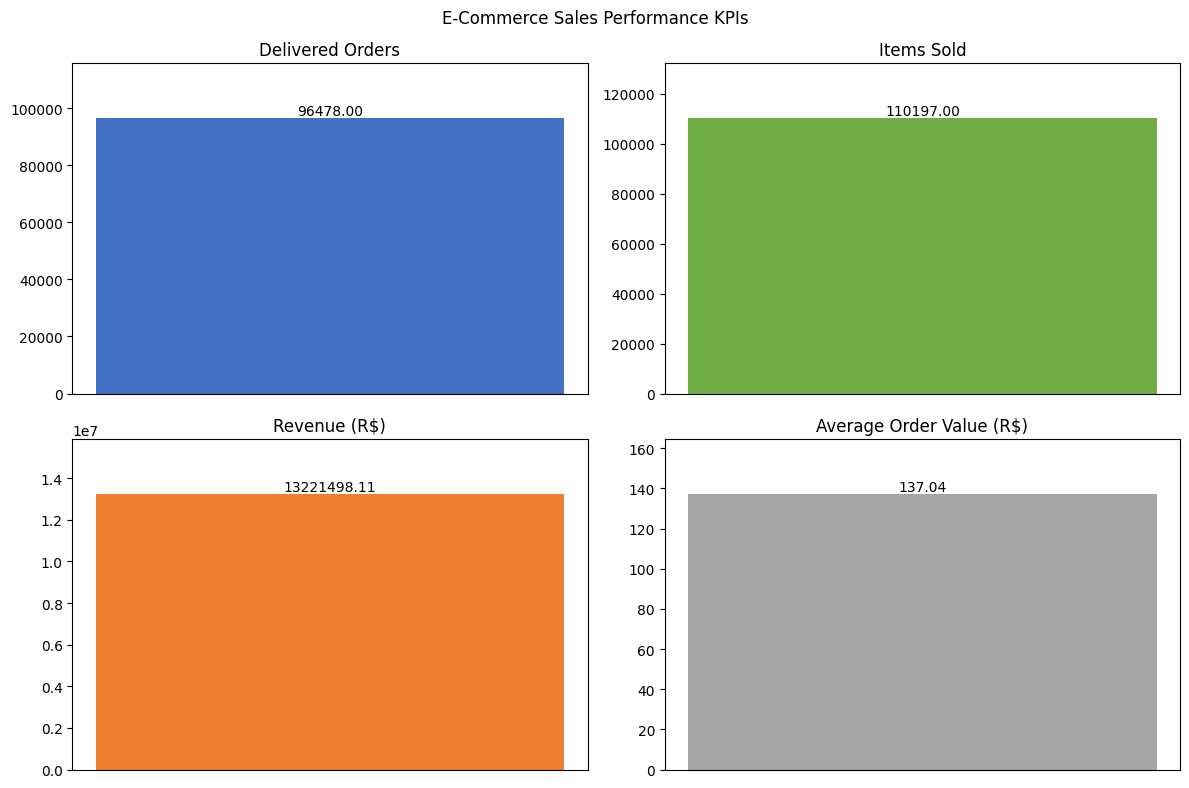

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

kpis = [
    ("Delivered Orders", total_orders, "#4472C4"),
    ("Items Sold", total_items, "#70AD47"),
    ("Revenue (R$)", total_revenue, "#ED7D31"),
    ("Average Order Value (R$)", average_order_value, "#A5A5A5")
]

for ax, (title, value, color) in zip(axes.flatten(), kpis):
    ax.bar([title], [value], color=color)
    ax.set_title(title)
    ax.bar_label(ax.containers[0], fmt='%.2f')
    ax.set_ylim(0, value * 1.2)
    ax.set_xticks([])

plt.suptitle("E-Commerce Sales Performance KPIs")
plt.tight_layout()
plt.show()

In [6]:
# Convert purchase date into datetime format
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp'],
    errors='coerce'
)

# Keep only delivered orders
delivered_orders = orders[
    orders['order_status'] == 'delivered'
].copy()

# Extract month from purchase date
delivered_orders['month'] = (
    delivered_orders['order_purchase_timestamp']
    .dt.to_period('M')
    .astype(str)
)

# Connect orders with their product prices
monthly_data = delivered_orders[
    ['order_id', 'month']
].merge(
    order_items[['order_id', 'price']],
    on='order_id',
    how='inner'
)

# Calculate monthly orders and revenue
monthly_sales = monthly_data.groupby('month').agg(
    total_orders=('order_id', 'nunique'),
    total_revenue=('price', 'sum')
).reset_index()

# Display results
print(monthly_sales.to_string(index=False))

  month  total_orders  total_revenue
2016-09             1         134.97
2016-10           265       40325.11
2016-12             1          10.90
2017-01           750      111798.36
2017-02          1653      234223.40
2017-03          2546      359198.85
2017-04          2303      340669.68
2017-05          3546      489338.25
2017-06          3135      421923.37
2017-07          3872      481604.52
2017-08          4193      554699.70
2017-09          4150      607399.67
2017-10          4478      648247.65
2017-11          7289      987765.37
2017-12          5513      726033.19
2018-01          7069      924645.00
2018-02          6555      826437.13
2018-03          7003      953356.25
2018-04          6798      973534.09
2018-05          6749      977544.69
2018-06          6099      856077.86
2018-07          6159      867953.46
2018-08          6351      838576.64


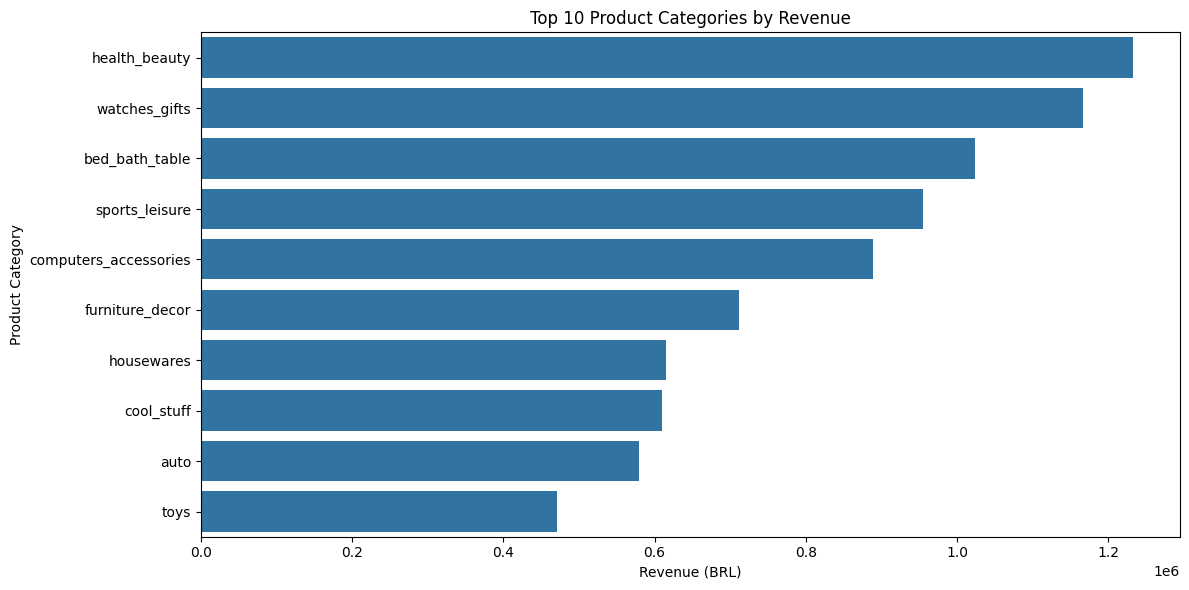

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x='total_revenue',
    y='product_category_name_english'
)

plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Revenue (BRL)')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [15]:
# Join order items with product categories
category_data = order_items.merge(
    products[['product_id', 'product_category_name_english']],
    on='product_id',
    how='left'
)

# Calculate revenue by category
category_sales = category_data.groupby(
    'product_category_name_english'
).agg(
    total_items=('product_id', 'count'),
    total_revenue=('price', 'sum')
).reset_index()

# Sort by revenue and select top 10
top_categories = category_sales.sort_values(
    by='total_revenue',
    ascending=False
).head(10)

print(top_categories.to_string(index=False))

product_category_name_english  total_items  total_revenue
                health_beauty         9670     1258681.34
                watches_gifts         5991     1205005.68
               bed_bath_table        11115     1036988.68
               sports_leisure         8641      988048.97
        computers_accessories         7827      911954.32
              furniture_decor         8334      729762.49
                   cool_stuff         3796      635290.85
                   housewares         6964      632248.66
                         auto         4235      592720.11
                 garden_tools         4347      485256.46


In [9]:
# Keep only items belonging to delivered orders
delivered_category_data = order_items[
    order_items['order_id'].isin(delivered_orders['order_id'])
].merge(
    products[['product_id', 'product_category_name_english']],
    on='product_id',
    how='left'
)

# Calculate category-wise performance
category_sales = delivered_category_data.groupby(
    'product_category_name_english'
).agg(
    total_items=('product_id', 'count'),
    total_revenue=('price', 'sum')
).reset_index()

# Get top 10 categories by revenue
top_categories = category_sales.sort_values(
    by='total_revenue',
    ascending=False
).head(10)

print(top_categories.to_string(index=False))

product_category_name_english  total_items  total_revenue
                health_beauty         9465     1233131.72
                watches_gifts         5859     1166176.98
               bed_bath_table        10953     1023434.76
               sports_leisure         8431      954852.55
        computers_accessories         7644      888724.61
              furniture_decor         8160      711927.69
                   housewares         6795      615628.69
                   cool_stuff         3718      610204.10
                         auto         4140      578966.65
                         toys         4030      471286.48


In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

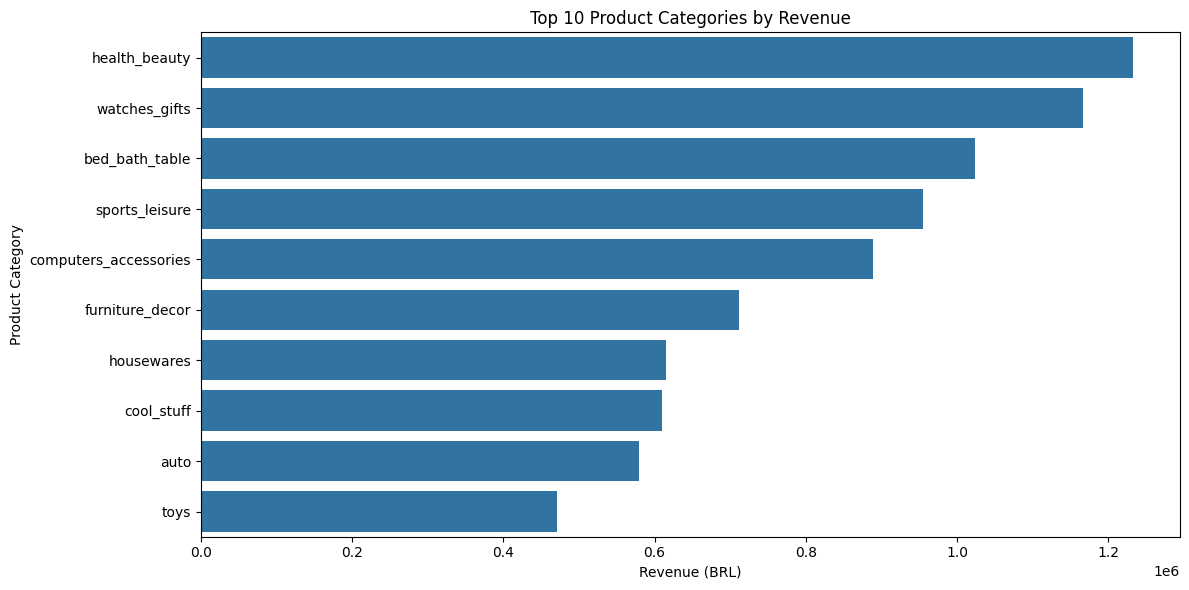

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x='total_revenue',
    y='product_category_name_english'
)

plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Revenue (BRL)')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [16]:
# Get delivered orders with customer IDs
customer_orders = delivered_orders[
    ['order_id', 'customer_id']
]

# Count delivered orders per customer
orders_per_customer = customer_orders.groupby(
    'customer_id'
)['order_id'].nunique()

# Calculate customer metrics
total_customers = len(orders_per_customer)

repeat_customers = (
    orders_per_customer > 1
).sum()

one_time_customers = (
    orders_per_customer == 1
).sum()

repeat_rate = (
    repeat_customers / total_customers
) * 100

print("Total Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customer Rate:", round(repeat_rate, 2), "%")

Total Customers: 96478
Repeat Customers: 0
One-Time Customers: 96478
Repeat Customer Rate: 0.0 %


In [17]:
# Connect delivered orders with unique customer IDs
customer_orders = delivered_orders[
    ['order_id', 'customer_id']
].merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Count orders placed by each unique customer
orders_per_customer = customer_orders.groupby(
    'customer_unique_id'
)['order_id'].nunique()

# Calculate customer metrics
total_customers = len(orders_per_customer)

repeat_customers = (orders_per_customer > 1).sum()

one_time_customers = (orders_per_customer == 1).sum()

repeat_rate = (repeat_customers / total_customers) * 100

print("Total Unique Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customer Rate:", round(repeat_rate, 2), "%")

Total Unique Customers: 93358
Repeat Customers: 2801
One-Time Customers: 90557
Repeat Customer Rate: 3.0 %


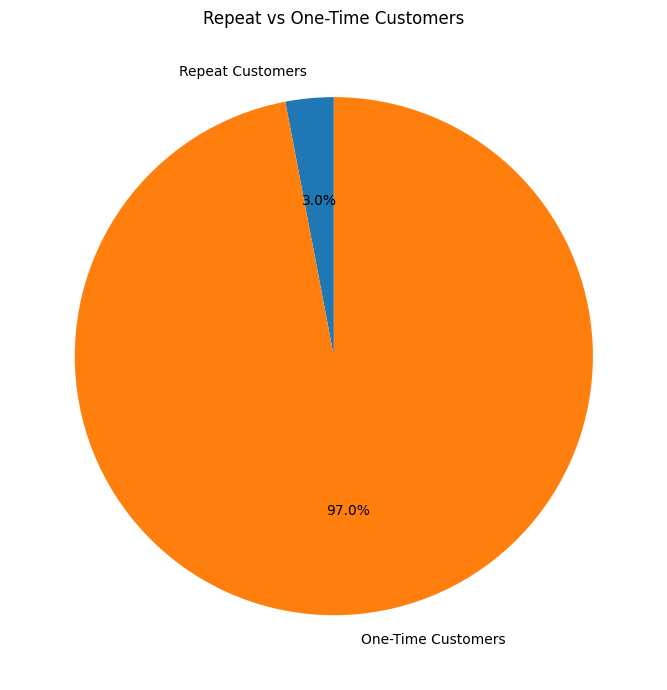

In [18]:
customer_labels = ['Repeat Customers', 'One-Time Customers']

customer_values = [
    repeat_customers,
    one_time_customers
]

plt.figure(figsize=(7, 7))

plt.pie(
    customer_values,
    labels=customer_labels,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Repeat vs One-Time Customers')
plt.tight_layout()
plt.show()

In [20]:
import numpy as np

# Select delivered orders with valid delivery dates
delivery_data = delivered_orders[
    ['order_id',
     'order_purchase_timestamp',
     'order_delivered_customer_date',
     'order_estimated_delivery_date']
].copy()

# Convert date columns
date_columns = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    delivery_data[col] = pd.to_datetime(
        delivery_data[col], errors='coerce'
    )

# Remove rows with missing delivery dates
delivery_data = delivery_data.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
)

# Calculate actual delivery time in days
delivery_data['delivery_days'] = (
    delivery_data['order_delivered_customer_date'] -
    delivery_data['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Identify late deliveries
delivery_data['delivery_status'] = np.where(
    delivery_data['order_delivered_customer_date'] >
    delivery_data['order_estimated_delivery_date'],
    'Late',
    'On Time'
)

# Calculate KPIs
average_delivery = delivery_data['delivery_days'].mean()

late_orders = (
    delivery_data['delivery_status'] == 'Late'
).sum()

total_delivery_orders = len(delivery_data)

late_rate = (late_orders / total_delivery_orders) * 100

on_time_rate = 100 - late_rate

print("Orders Analyzed:", total_delivery_orders)
print("Average Delivery Time:", round(average_delivery, 2), "days")
print("Late Orders:", late_orders)
print("Late Delivery Rate:", round(late_rate, 2), "%")
print("On-Time Delivery Rate:", round(on_time_rate, 2), "%")

Orders Analyzed: 96470
Average Delivery Time: 12.56 days
Late Orders: 7826
Late Delivery Rate: 8.11 %
On-Time Delivery Rate: 91.89 %


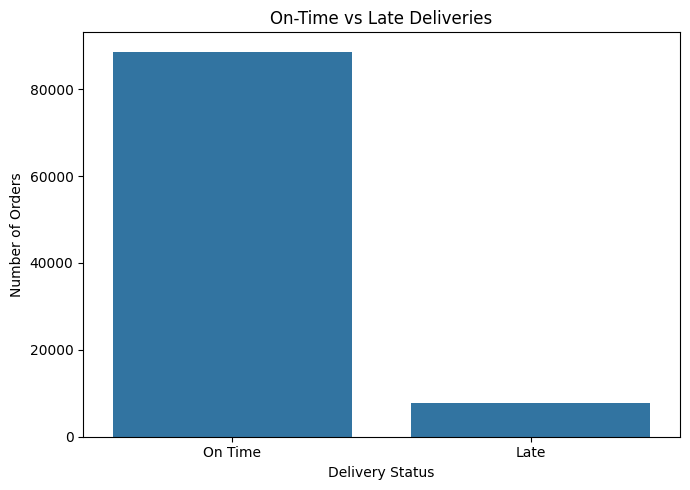

In [21]:
delivery_counts = delivery_data['delivery_status'].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values
)

plt.title('On-Time vs Late Deliveries')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

In [22]:
# Calculate one average review score per order
order_reviews = reviews.groupby('order_id').agg(
    average_review_score=('review_score', 'mean')
).reset_index()

# Connect delivery status with review scores
delivery_reviews = delivery_data[
    ['order_id', 'delivery_status']
].merge(
    order_reviews,
    on='order_id',
    how='inner'
)

# Compare average ratings
review_comparison = delivery_reviews.groupby(
    'delivery_status'
).agg(
    total_orders=('order_id', 'nunique'),
    average_review=('average_review_score', 'mean')
).reset_index()

print(review_comparison.to_string(index=False))

delivery_status  total_orders  average_review
           Late          7661        2.566506
        On Time         88163        4.294292


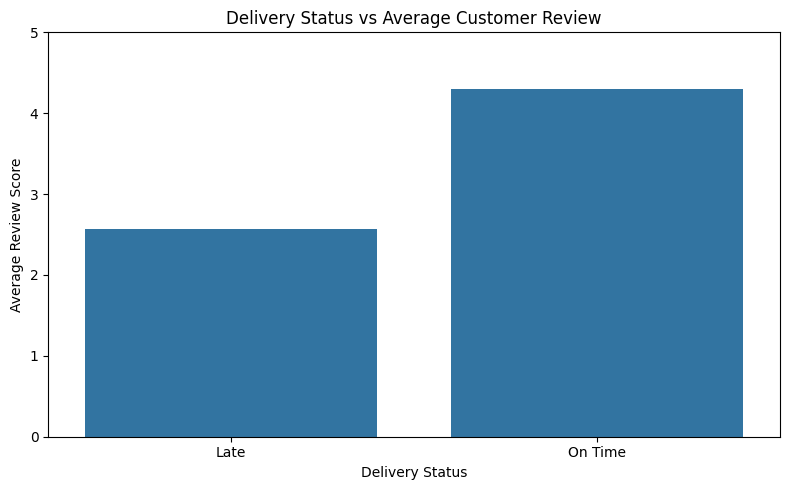

In [23]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=review_comparison,
    x='delivery_status',
    y='average_review'
)

plt.title('Delivery Status vs Average Customer Review')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

In [24]:
# Join payment records with delivered orders
delivered_payments = payments[
    payments['order_id'].isin(delivered_orders['order_id'])
].copy()

# Calculate payment method performance
payment_analysis = delivered_payments.groupby(
    'payment_type'
).agg(
    total_payment_records=('order_id', 'count'),
    total_orders=('order_id', 'nunique'),
    total_payment_value=('payment_value', 'sum')
).reset_index()

# Calculate percentage contribution
total_payment_value = payment_analysis['total_payment_value'].sum()

payment_analysis['revenue_share_pct'] = (
    payment_analysis['total_payment_value'] /
    total_payment_value * 100
)

payment_analysis = payment_analysis.sort_values(
    by='total_payment_value',
    ascending=False
)

print(payment_analysis.round(2).to_string(index=False))

payment_type  total_payment_records  total_orders  total_payment_value  revenue_share_pct
 credit_card                  74586         74304          12101094.88              78.46
      boleto                  19191         19191           2769932.58              17.96
     voucher                   5493          3679            343013.19               2.22
  debit_card                   1486          1485            208421.12               1.35


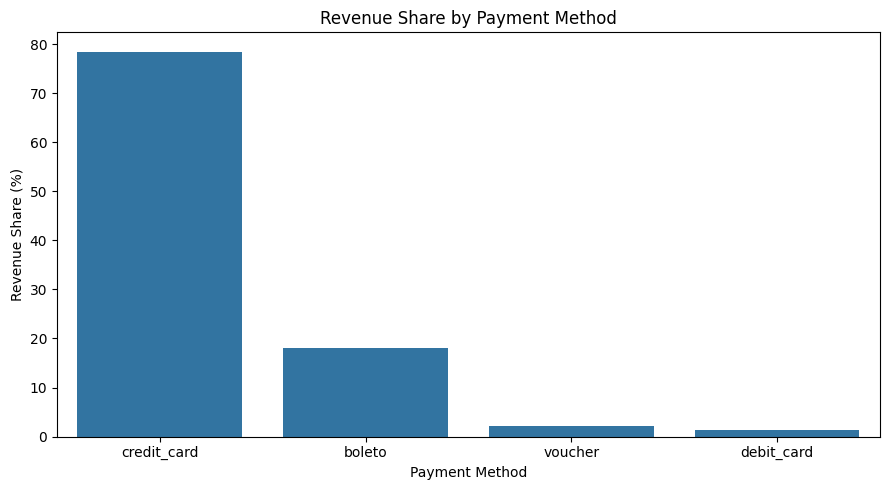

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=payment_analysis,
    x='payment_type',
    y='revenue_share_pct'
)

plt.title('Revenue Share by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Revenue Share (%)')

plt.tight_layout()
plt.show()

In [26]:
# Keep items from delivered orders only
delivered_items = order_items[
    order_items['order_id'].isin(delivered_orders['order_id'])
].copy()

# Connect order items with seller details
seller_data = delivered_items.merge(
    sellers[['seller_id', 'seller_state']],
    on='seller_id',
    how='left'
)

# Calculate seller-wise revenue
seller_analysis = seller_data.groupby(
    ['seller_id', 'seller_state']
).agg(
    total_orders=('order_id', 'nunique'),
    total_items=('product_id', 'count'),
    total_revenue=('price', 'sum')
).reset_index()

# Find top 10 sellers
top_sellers = seller_analysis.sort_values(
    by='total_revenue',
    ascending=False
).head(10)

print(top_sellers.round(2).to_string(index=False))

                       seller_id seller_state  total_orders  total_items  total_revenue
4869f7a5dfa277a7dca6462dcf3b52b2           SP          1124         1148      226987.93
53243585a1d6dc2643021fd1853d8905           BA           348          400      217940.44
4a3ca9315b744ce9f8e9374361493884           SP          1772         1949      196882.12
fa1c13f2614d7b5c4749cbc52fecda94           SP           578          579      190917.14
7c67e1448b00f6e969d365cea6b010ab           SP           973         1355      186570.05
7e93a43ef30c4f03f38b393420bc753a           SP           319          322      165981.49
da8622b14eb17ae2831f4ac5b9dab84a           SP          1311         1548      159816.87
7a67c85e85bb2ce8582c35f2203ad736           SP          1145         1155      139658.69
1025f0e2d44d7041d6cf58b6550e0bfa           SP           910         1420      138208.56
955fee9216a65b617aa5c0531780ce60           SP          1261         1472      131836.71


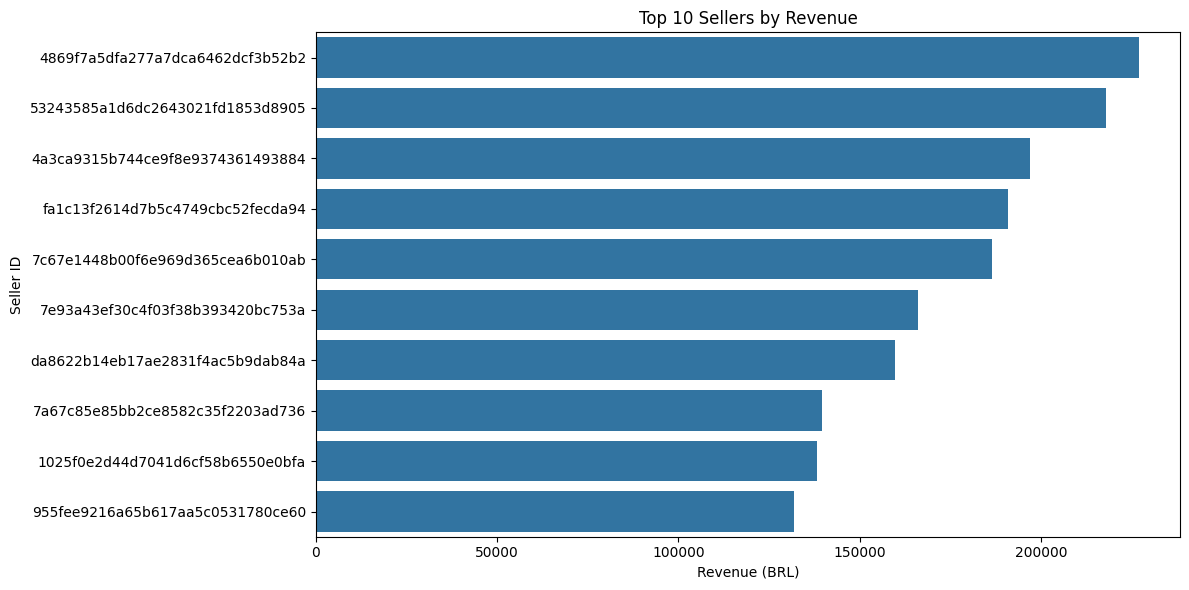

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_sellers,
    x='total_revenue',
    y='seller_id'
)

plt.title('Top 10 Sellers by Revenue')
plt.xlabel('Revenue (BRL)')
plt.ylabel('Seller ID')

plt.tight_layout()
plt.show()

In [28]:
# Calculate revenue by seller state
state_analysis = seller_data.groupby(
    'seller_state'
).agg(
    total_sellers=('seller_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_items=('product_id', 'count'),
    total_revenue=('price', 'sum')
).reset_index()

# Sort by revenue
state_analysis = state_analysis.sort_values(
    by='total_revenue',
    ascending=False
)

# Calculate revenue contribution percentage
state_analysis['revenue_share_pct'] = (
    state_analysis['total_revenue'] /
    state_analysis['total_revenue'].sum()
) * 100

print(state_analysis.round(2).to_string(index=False))

seller_state  total_sellers  total_orders  total_items  total_revenue  revenue_share_pct
          SP           1769         68641        78604     8509511.46              64.36
          PR            335          7512         8487     1232096.99               9.32
          MG            236          7735         8603      977866.31               7.40
          RJ            163          4227         4685      820611.59               6.21
          SC            184          3603         4000      613591.65               4.64
          RS            125          1962         2169      373412.08               2.82
          BA             18           550          624      277925.51               2.10
          DF             30           808          883       94840.31               0.72
          PE              9           403          445       91164.15               0.69
          GO             39           451          508       64806.59               0.49
          ES         

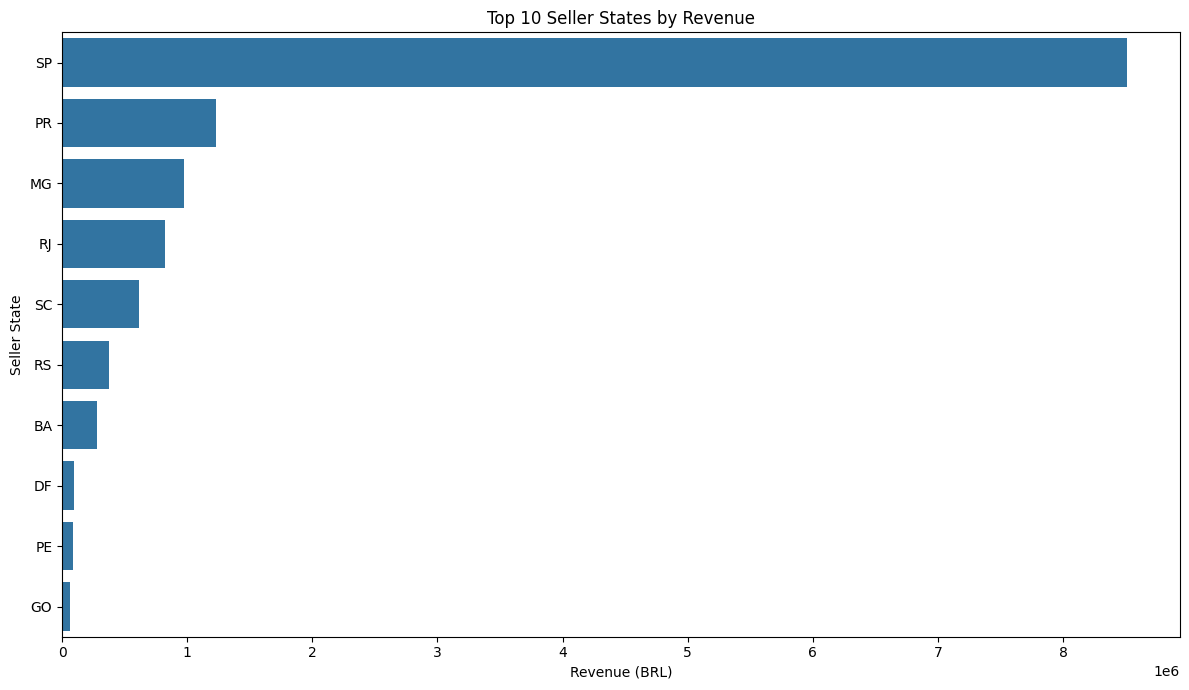

In [29]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=state_analysis.head(10),
    x='total_revenue',
    y='seller_state'
)

plt.title('Top 10 Seller States by Revenue')
plt.xlabel('Revenue (BRL)')
plt.ylabel('Seller State')

plt.tight_layout()
plt.show()